# Notebook 7b — FCC-ee: chromatic tune scan and final-doublet misalignments

Load the nominal and larger IP beta rings saved by notebook 7, with the same nominal tunes and linear chromaticities. Apply independent Gaussian horizontal and vertical offsets with **5 µm RMS** only to the final-doublet quadrupoles on both sides of all four IPs, using the **same error realization in both optics**. Plot the uncorrected closed orbit and compare its RMS around the ring.

## Your tasks

1. Load `fccee_z_nominal.json` and `fccee_z_matched.json`.
2. Prepare the rings for an uncorrected-orbit comparison with radiation switched off and the nonlinear magnets active.
3. Scan the horizontal and vertical tunes over −0.8% to +0.8% momentum offset in the aligned rings.
4. Generate reproducible random final-doublet offsets and apply the same offsets to the corresponding magnets in both rings.
5. Calculate the on-momentum closed orbit and plot $x(s)$ and $y(s)$.
6. Measure the horizontal and vertical orbit RMS, weighted by distance around the ring.

Run the JSON export cells in notebook 7 before starting this notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

### Load the two optics

In [2]:
lines = {
    'Nominal': xt.load('fccee_z_nominal.json'),
    'Matched': xt.load('fccee_z_matched.json'),
}
for line in lines.values():
    line.configure_radiation(model=None)

Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Done loading line from dict.           


Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Done loading line from dict.           


### Tunes versus momentum offset

Scan the aligned rings before applying the quadrupole errors, to compare their intrinsic chromatic behavior. The auxiliary sextupoles retain their original strengths. Both rings have the same tunes and linear chromaticities at $\delta=0$; departures from the dashed linear approximation show the higher-order terms.

A stable periodic Twiss solution is unavailable at some off-momentum points. Leave these as gaps and mark their momentum offsets with crosses along the bottom of the plot.

In [3]:
delta_values = np.linspace(-0.008, 0.008, 41)
qx_vs_delta = {}
qy_vs_delta = {}

for label, line in lines.items():
    qx = np.full(len(delta_values), np.nan)
    qy = np.full(len(delta_values), np.nan)
    for i, delta in enumerate(delta_values):
        try:
            tw_delta = line.twiss4d(delta0=delta, chrom=False)
            qx[i], qy[i] = tw_delta.qx, tw_delta.qy
        except ValueError as error:
            if not (str(error).startswith('Invalid n') or 'unstable' in str(error)):
                raise
    qx_vs_delta[label] = qx
    qy_vs_delta[label] = qy
    print(f'{label}: {np.count_nonzero(np.isfinite(qx))}/{len(delta_values)} '
          'stable Twiss solutions')

Nominal: 41/41 stable Twiss solutions
Matched: 28/41 stable Twiss solutions


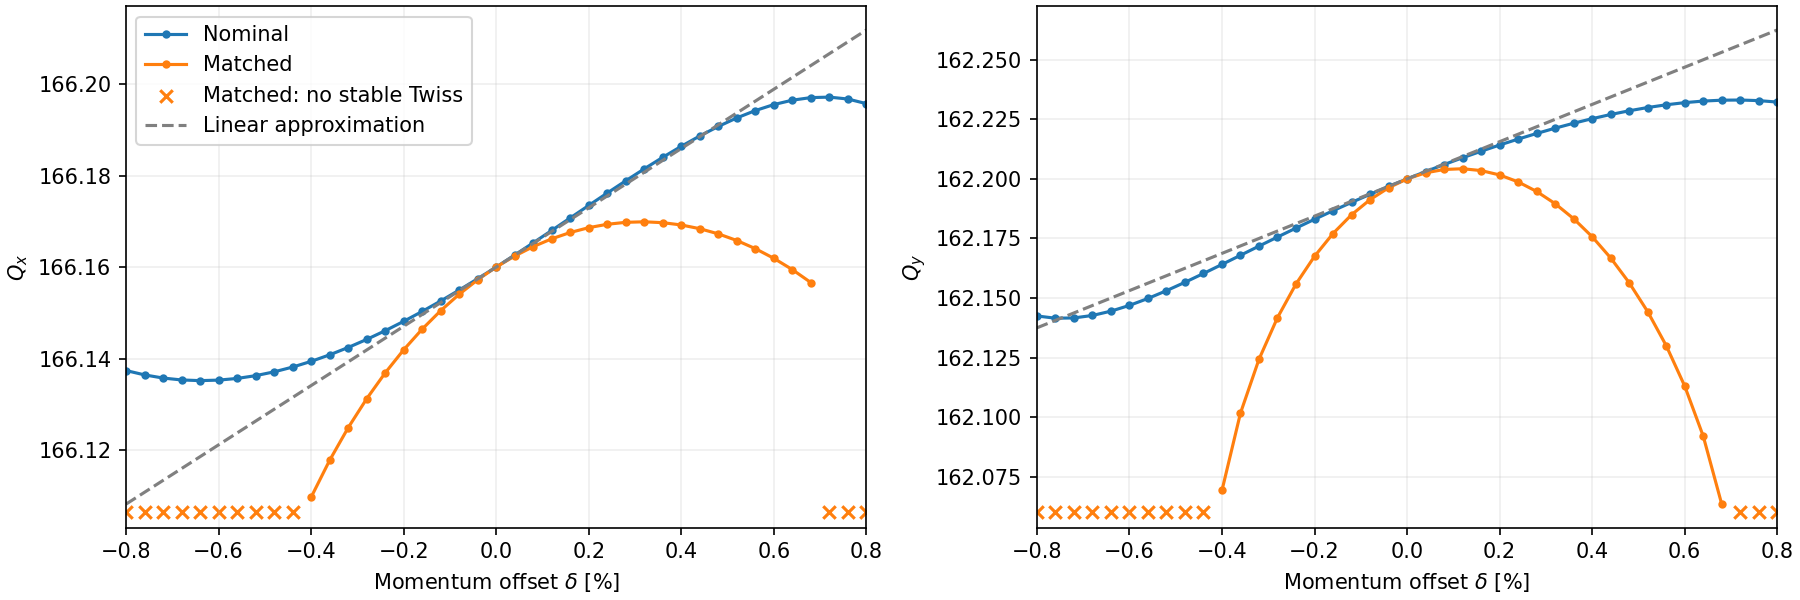

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
tw_reference = lines['Nominal'].twiss4d(delta_chrom=1e-6)

for ax, tunes, plane in zip(axes, [qx_vs_delta, qy_vs_delta], ['x', 'y']):
    for label, q in tunes.items():
        curve, = ax.plot(100 * delta_values, q, '.-', label=label)
        failed = ~np.isfinite(q)
        if np.any(failed):
            ax.scatter(100 * delta_values[failed], np.full(np.sum(failed), 0.03),
                       transform=ax.get_xaxis_transform(), marker='x',
                       color=curve.get_color(), label=f'{label}: no stable Twiss')

    ax.plot(100 * delta_values,
            tw_reference['q' + plane] + tw_reference['dq' + plane] * delta_values,
            '--', color='grey', label='Linear approximation')
    ax.set_xlabel(r'Momentum offset $\delta$ [%]')
    ax.set_ylabel(f'$Q_{plane}$')
    ax.set_xlim(-0.8, 0.8)
    ax.ticklabel_format(axis='y', useOffset=False)
    ax.grid(alpha=0.2)
axes[0].legend()


Correcting the linear chromaticity fixes the slope at zero momentum offset. It does not constrain the curvature or guarantee off-momentum stability. This plot describes tunes about the closed orbit, not finite-amplitude particle survival.

### Misalign only the final doublets

Select the `QD0` sections a–c and `QF1` sections a–d on the left and right of each IP: 56 quadrupole elements. Apply independent x and y offsets to each section, using a fixed random seed and the same offsets in both rings. All other quadrupoles stay aligned.

The offsets follow a zero-mean Gaussian with standard deviation 5 µm; the finite sample RMS need not be exactly 5 µm.

In [5]:
tt = lines['Nominal'].get_table()
quad_names = tt.rows[r'(qd0[abc]|qf1[abcd])[lr]\.[0-3]'].name

sigma_shift = 5e-6
rng = np.random.default_rng(2026)
shift_x = rng.normal(0, sigma_shift, len(quad_names))
shift_y = rng.normal(0, sigma_shift, len(quad_names))

for line in lines.values():
    for name, dx, dy in zip(quad_names, shift_x, shift_y):
        line[name].shift_x = dx
        line[name].shift_y = dy

print(f'Final-doublet elements shifted: {len(quad_names)}')
print(f'Applied offset RMS: x = {1e6 * np.sqrt(np.mean(shift_x**2)):.2f} µm, '
      f'y = {1e6 * np.sqrt(np.mean(shift_y**2)):.2f} µm')

Final-doublet elements shifted: 56
Applied offset RMS: x = 5.08 µm, y = 5.20 µm


### Calculate and plot the closed orbits

Keep the nonlinear magnets active and use `twiss4d(only_orbit=True)` at `delta0=0` to calculate the periodic orbit. No orbit correction is applied.

In [6]:
orbits = {}
for label, line in lines.items():
    orbits[label] = line.twiss4d(delta0=0, only_orbit=True)

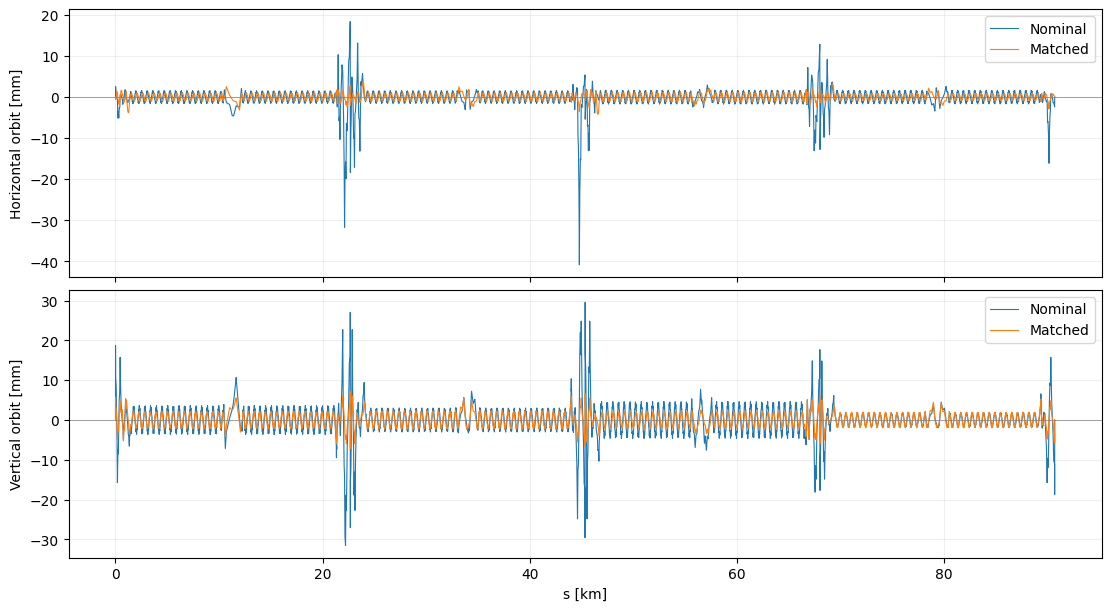

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                         layout='constrained')
for label, tw in orbits.items():
    axes[0].plot(tw.s / 1e3, tw.x * 1e3, label=label, linewidth=0.8)
    axes[1].plot(tw.s / 1e3, tw.y * 1e3, label=label, linewidth=0.8)
axes[0].set_ylabel('Horizontal orbit [mm]')
axes[1].set_ylabel('Vertical orbit [mm]')
axes[1].set_xlabel('s [km]')
for ax in axes:
    ax.axhline(0, color='grey', linewidth=0.5)
    ax.grid(alpha=0.2)
    ax.legend()

### Measure the orbit RMS

Compute the RMS relative to the design orbit, without subtracting the mean:

$$x_{\rm RMS}=\sqrt{\frac{1}{C}\int_0^C x(s)^2\,ds},\qquad
  y_{\rm RMS}=\sqrt{\frac{1}{C}\int_0^C y(s)^2\,ds}.$$

Use trapezoidal integration over the orbit table. Weighting by distance prevents dense groups of markers or short elements from dominating the result.

In [8]:
orbit_rms = {}
print(f'{"Optics":<12} {"x RMS [mm]":>14} {"y RMS [mm]":>14}')
for label, tw in orbits.items():
    circumference = tw.s[-1] - tw.s[0]
    rms_x = np.sqrt(np.trapezoid(tw.x**2, tw.s) / circumference)
    rms_y = np.sqrt(np.trapezoid(tw.y**2, tw.s) / circumference)
    orbit_rms[label] = np.array([rms_x, rms_y])
    print(f'{label:<12} {rms_x * 1e3:14.3f} {rms_y * 1e3:14.3f}')

ratio = orbit_rms['Matched'] / orbit_rms['Nominal']
print(f'Matched / nominal RMS: x = {ratio[0]:.3f}, y = {ratio[1]:.3f}')

Optics           x RMS [mm]     y RMS [mm]
Nominal               2.558          3.817
Matched               0.822          1.640
Matched / nominal RMS: x = 0.322, y = 0.430


The final-doublet offsets are identical in both rings. Compare the RMS values to see how increasing the IP beta changes the sensitivity to alignment errors. Try another random seed to repeat the comparison.